# 05 — Torneo final: VAE vs Flow Matching vs baseline, con juez AST

**Proyecto Final — Inteligencia Artificial II (UNCuyo)**  
**Alumno:** Enzo Palau (Legajo 13686)

## Objetivo

Poner a competir los generadores del proyecto bajo un mismo juez y un mismo protocolo:

- **C-VAE** (NB03): `muestras_generadas.npz`.
- **Flow Matching condicional** (NB04): `muestras_cfm.npz`.
- **Baseline de media**: el mel promedio de cada `(familia, pitch)` en `train`, como control inferior.
- **Referencia real**: el split `test`, que ningún generador vio y que el NB03/NB04 no tocaron.

El juez oficial es el `AST-FullFT` del NB02 (AST de AudioSet con las últimas 4 capas y la cabeza afinadas, `max_length=256`), el mejor de los tres evaluadores entrenados allí (Accuracy 0.9481 / F1 macro 0.9316 en `test`). El notebook se parametriza con la variable `JUEZ` de la sección 1: se puede correr también con `AST-HeadOnly` (backbone congelado, cabeza lineal; Accuracy 0.9261 / F1 macro 0.8998) como **control de sensibilidad** a la elección del juez. Cada corrida escribe en su propia carpeta `torneo_output_<JUEZ>`.

## Qué se mide

La pregunta del torneo es una sola: **dado un mel generado, ¿el juez recupera la familia de instrumento que se pidió?** Eso es exactamente lo que evalúa el anteproyecto: Accuracy sobre las muestras generadas mayor al 50 % y superior al baseline de media. Se reportan además F1 macro, confianza media del juez, accuracy por condición y por familia, y matrices de confusión.

## Qué se va a producir

1. La accuracy del juez sobre `test` (techo) y sobre el subconjunto de `test` con las mismas 20 condiciones que los generadores.
2. La tabla del torneo con las 80 muestras de cada generador.
3. Mapas de acierto por `(familia, pitch)` y recall por familia, para ver dónde falla cada modelo.
4. Un experimento de **selección por duración**: de las 4 semillas por condición se elige la que más se acerca a la duración mediana real. Cuesta cero GPU y ataca la única variable que los generadores no reciben como condición.
5. Un control de calibración: se reescala cada set generado a la media y el desvío de `test` y se vuelve a evaluar, para estimar cuánto del acierto depende de la apariencia global y no del contenido armónico.
6. La misma nota sintetizada por los cuatro caminos con el vocoder del proyecto, para escucharla y verla, no solo medirla.

## Protocolo y honestidad

Los generadores no se entrenaron con el juez ni con `test`. El juez sí se entrenó con `train`, igual que los generadores, así que no hay ventaja de información para ninguno. La comparación es por cantidad de muestras y condiciones idénticas: 4 familias × 5 alturas × 4 semillas = 80 mels de 128×128 por generador, con el mismo vocoder y la misma escala `[-1, 1]`.

## 1. Configuración del entorno

### ¿Qué se hace a continuación?
Se importan las librerías, se fija la semilla, se detecta el dispositivo y se definen las rutas de entrada y salida. Los tres artefactos que consume el torneo (el checkpoint del juez y las muestras de cada generador) se buscan y se verifican en el bloque 1.1.

### ¿Por qué se hace?
El error más común de un notebook de cierre es asumir una ruta. Acá la configuración solo deja el entorno listo y la resolución de los artefactos queda aislada en 1.1, que imprime qué encontró y qué no antes de gastar tiempo en inferencia.

In [85]:
import os
import sys
import json
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings('ignore')

# ── Semilla global ──────────────────────────────────────────────────────────
SEED = 42

# ── Juez a usar ─────────────────────────────────────────────────────────────
# Oficial (según juez_config.json del NB02): 'AST-FullFT'.
# Para el control de sensibilidad, cambiar a 'AST-HeadOnly' y volver a correr.
JUEZ = 'AST-FullFT'
CFG_JUEZ = {
    'AST-HeadOnly': dict(freeze_backbone=True,  max_length=1024),
    'AST-FullFT':   dict(freeze_backbone=False, max_length=256),
}
assert JUEZ in CFG_JUEZ, f'JUEZ debe ser uno de {list(CFG_JUEZ)}'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ── Detección de entorno ────────────────────────────────────────────────────
IN_KAGGLE = os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None
IN_COLAB = 'google.colab' in sys.modules


def _encontrar_data_dir():
    '''Busca la carpeta que contiene los .npz procesados.'''
    candidatos = [
        Path('/kaggle/input/nsynth-processed-palau'),
        Path('/kaggle/input/datasets/enzopalau/nsynth-processed-palau'),
        Path('/kaggle/input/nsynth-processed'),
        Path('/content/drive/MyDrive/IA2_Proyecto_Instrumentos/processed'),
        Path('./data_processed/processed'),
        Path('../tensores'),
        Path('../../tensores'),
        Path('./tensores'),
    ]
    for p in candidatos:
        if p.exists() and any(p.glob('*.npz')):
            return p
    raiz = Path('/kaggle/input')
    if raiz.exists():
        matches = list(raiz.rglob('nsynth_processed_train.npz'))
        if matches:
            return matches[0].parent
    return Path('./data_processed/processed')


DATA_DIR = _encontrar_data_dir()

if IN_KAGGLE:
    OUTPUT_DIR = Path(f'/kaggle/working/torneo_output_{JUEZ}')
elif IN_COLAB:
    OUTPUT_DIR = Path(f'/content/torneo_output_{JUEZ}')
else:
    OUTPUT_DIR = Path(f'./torneo_output_{JUEZ}')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


RAIZ_INPUT = Path('/kaggle/input')


def _norm(nombre):
    '''Nombre comparable: 'muestras-cfm' y 'muestras_cfm' dan lo mismo.'''
    return ''.join(ch for ch in nombre.lower() if ch.isalnum())


class _NpzDescomprimido(dict):
    '''Se comporta como el objeto de np.load si Kaggle descomprimió el .npz.'''

    @property
    def files(self):
        return list(self.keys())


def cargar_npz(ruta):
    '''Carga un .npz, venga como archivo o como carpeta descomprimida.'''
    ruta = Path(ruta)
    if ruta.is_file():
        return np.load(ruta)
    if not ruta.is_dir():
        raise FileNotFoundError(ruta)
    datos = _NpzDescomprimido()
    for f in sorted(ruta.glob('*.npy')):
        datos[f.stem] = np.load(f)
    if 'mels' not in datos:
        raise FileNotFoundError(
            f'{ruta} no parece un .npz descomprimido: no tiene mels.npy')
    print(f'[INFO] {ruta.name}/: .npz descomprimido por Kaggle '
          f'({", ".join(datos.files)})')
    return datos


# ── Dispositivo ─────────────────────────────────────────────────────────────
if torch.cuda.is_available():
    device = torch.device('cuda:0')
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)} | '
          f'VRAM: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    device = torch.device('cpu')
    print('[ADVERTENCIA] Sin GPU: el AST va a tardar mucho más (pero funciona).')
use_amp = (device.type == 'cuda')

print(f'[INFO] DATA_DIR   = {DATA_DIR}')
print(f'[INFO] OUTPUT_DIR = {OUTPUT_DIR}')
print(f'[INFO] RAIZ_INPUT = {RAIZ_INPUT}')

[INFO] GPU: Tesla T4 | VRAM: 15.6 GB
[INFO] DATA_DIR   = /kaggle/input/datasets/enzopalau/nsynth-processed-palau
[INFO] OUTPUT_DIR = /kaggle/working/torneo_output_AST-FullFT
[INFO] RAIZ_INPUT = /kaggle/input


## 1.1 Importar los artefactos de las corridas anteriores

### ¿Qué se hace a continuación?
Se buscan los artefactos que dejaron los notebooks anteriores —`juez_<JUEZ>_best.pt` (NB02), `muestras_cfm.npz` (NB04) y `muestras_generadas.npz` (NB03)— y se copian a `/kaggle/working` en las carpetas que espera el resto del torneo: `juez_output/`, `cfm_output/` y `vae_output/`. Cada candidato se prueba leyéndolo antes de aceptarlo: el `.npz` tiene que traer `mels`, `families` y `pitches`, y el `.pt` tiene que cargar como `state_dict`.

### ¿Por qué se hace?
Los outputs de un notebook se adjuntan como input (`Add Input → Your work`) y llegan como archivos reales. Los datasets, en cambio, descomprimen los `.npz` y los `.pt` porque los dos son zips, y un `.pt` descomprimido puede quedar sin la carpeta `data/`, que es donde están los pesos. Importar y verificar una sola vez acá evita que el torneo arranque con un artefacto roto y falle recién al cargar el juez. Además todo queda en `working`, así que las celdas siguientes no dependen de cómo se montó el input.


In [86]:
# ── Importar los artefactos de las corridas anteriores ─────────────────────
# Add Input → Your work → NB02 / NB03 / NB04. Los outputs de un notebook se
# montan como archivos reales; si el artefacto llegó como dataset, Kaggle lo
# descomprimió (los .npz y los .pt son zips) y acá se rearma. Todo queda
# copiado en /kaggle/working, que es lo que leen las celdas siguientes.
import shutil
import tempfile
import zipfile


def _rearmar_pt(carpeta, destino):
    '''Re-arma el zip de un .pt que Kaggle descomprimió.

    Se conservan las rutas relativas tal cual quedaron al descomprimir. Si la
    carpeta todavía trae la raíz original ('juez_X/data.pkl') se usa esa; si
    los archivos quedaron sueltos ('data.pkl' al tope) se les pone el nombre
    de la carpeta como raíz, porque torch no acepta un zip sin prefijo.
    '''
    carpeta = Path(carpeta)
    pkl = next(iter(carpeta.rglob('data.pkl')), None)
    if pkl is None:
        raise FileNotFoundError(f'{carpeta}: no parece un .pt descomprimido')
    if not (pkl.parent / 'data').is_dir() or not (pkl.parent / 'version').exists():
        raise FileNotFoundError(
            f'{carpeta}: el checkpoint descomprimido está incompleto (le falta '
            'data/ con los pesos o version). Subilo como archivo '
            '(Add Input → Your work) en vez de dataset.')
    anidado = pkl.parent.relative_to(carpeta).parts
    prefijo = '' if anidado else f'{carpeta.name}/'
    destino = Path(destino)
    destino.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(destino, 'w', zipfile.ZIP_STORED) as z:
        for f in sorted(carpeta.rglob('*')):
            if f.is_file():
                z.write(f, prefijo + f.relative_to(carpeta).as_posix())


def cargar_state_dict(ruta, dev='cpu'):
    '''state_dict desde un .pt, venga como archivo o como carpeta descomprimida.'''
    ruta = Path(ruta)
    if ruta.is_dir():
        tmp = Path(tempfile.mkdtemp()) / f'{ruta.name}.pt'
        _rearmar_pt(ruta, tmp)
        ruta = tmp
    try:
        return torch.load(ruta, map_location=dev, weights_only=True)
    except TypeError:  # torch viejo, sin el argumento weights_only
        return torch.load(ruta, map_location=dev)


def _verificar(ruta, tipo):
    '''Lee el artefacto y devuelve True si tiene lo que el torneo espera.'''
    try:
        if tipo == 'npz':
            datos = cargar_npz(ruta)
            faltan = [k for k in ('mels', 'families', 'pitches')
                      if k not in datos.files]
            if faltan:
                print(f'[ADVERTENCIA] {ruta}: le faltan las claves {faltan}')
                return False
            print(f'      {Path(ruta).name}: mels {tuple(datos["mels"].shape)} | '
                  f'{", ".join(datos.files)}')
        else:
            estado = cargar_state_dict(ruta)
            if not isinstance(estado, dict) or not estado:
                print(f'[ADVERTENCIA] {ruta}: no parece un state_dict')
                return False
            print(f'      {Path(ruta).name}: {len(estado)} tensores')
    except Exception as e:
        print(f'[ADVERTENCIA] {ruta}: {type(e).__name__}: {e}')
        return False
    return True


def _candidatos(nombre, subcarpeta, tipo):
    '''Rutas donde puede estar el artefacto, en orden de preferencia.'''
    tallo = Path(nombre).stem
    rutas = [
        OUTPUT_DIR.parent / subcarpeta / nombre,
        OUTPUT_DIR.parent / subcarpeta / tallo,
        OUTPUT_DIR.parent / nombre,
        OUTPUT_DIR.parent / tallo,
    ]
    buscados = {_norm(nombre), _norm(tallo)}
    raices = [OUTPUT_DIR.parent]
    if RAIZ_INPUT.exists():
        raices.append(RAIZ_INPUT)
    for raiz in raices:
        rutas += [p for p in sorted(raiz.rglob('*'))
                  if _norm(p.name) in buscados]
    vistos, salida = set(), []
    for p in rutas:
        p = Path(p)
        if p in vistos:
            continue
        vistos.add(p)
        if p.is_file():
            salida.append(p)
        elif p.is_dir() and ((tipo == 'npz' and any(p.glob('*.npy')))
                             or (tipo == 'pt'
                                 and next(iter(p.rglob('data.pkl')), None))):
            salida.append(p)
    return salida


def importar(nombre, subcarpeta, tipo):
    '''Copia (o rearma) el artefacto válido en working y lo verifica.

    Se prueba cada candidato hasta que uno se lea bien: así un checkpoint
    viejo o incompleto que haya quedado en working no le gana al bueno que
    está montado como input.
    '''
    destino = OUTPUT_DIR.parent / subcarpeta / nombre
    for origen in _candidatos(nombre, subcarpeta, tipo):
        print(f'[INFO] {nombre}: probando {origen}')
        if not _verificar(origen, tipo):
            continue
        if origen.resolve() != destino.resolve():
            destino.parent.mkdir(parents=True, exist_ok=True)
            if origen.is_dir() and tipo == 'npz':
                np.savez_compressed(destino, **cargar_npz(origen))
            elif origen.is_dir():
                _rearmar_pt(origen, destino)
            else:
                shutil.copy2(origen, destino)
            print(f'[OK] {subcarpeta}/{nombre}  <-  {origen}')
        else:
            print(f'[OK] {subcarpeta}/{nombre}  (ya estaba en working)')
        return destino
    return None


RUTA_JUEZ = importar(f'juez_{JUEZ}_best.pt', 'juez_output', 'pt')
RUTA_CFM = importar('muestras_cfm.npz', 'cfm_output', 'npz')
RUTA_VAE = importar('muestras_generadas.npz', 'vae_output', 'npz')

print()
for _etq, _r in (('Juez', RUTA_JUEZ), ('CFM', RUTA_CFM), ('VAE', RUTA_VAE)):
    print(f'[INFO] {_etq:4s} = {_r}')

if RUTA_JUEZ is None:
    raise FileNotFoundError(
        f'No se encontró juez_{JUEZ}_best.pt que se pueda cargar. Adjuntá la '
        'salida del NB02 con Add Input → Your work: los outputs de notebook se '
        'montan como archivos, mientras que un dataset descomprime el .pt y '
        'puede dejarlo sin los pesos.')
if RUTA_CFM is None:
    raise FileNotFoundError(
        'No se encontró muestras_cfm.npz que se pueda cargar. Adjuntá la '
        'salida del NB04 (Add Input → Your work) o corré el NB04 en esta '
        'misma sesión.')
if RUTA_VAE is None:
    print('[ADVERTENCIA] No se encontró muestras_generadas.npz (VAE). '
          'El torneo sigue sin esa fila.')


[INFO] juez_AST-FullFT_best.pt: probando /kaggle/working/juez_output/juez_AST-FullFT_best.pt
      juez_AST-FullFT_best.pt: 203 tensores
[OK] juez_output/juez_AST-FullFT_best.pt  (ya estaba en working)
[INFO] muestras_cfm.npz: probando /kaggle/working/cfm_output/muestras_cfm.npz
      muestras_cfm.npz: mels (80, 1, 128, 128) | families, mels, pitches, seeds, steps
[OK] cfm_output/muestras_cfm.npz  (ya estaba en working)
[INFO] muestras_generadas.npz: probando /kaggle/working/vae_output/muestras_generadas.npz
      muestras_generadas.npz: mels (80, 1, 128, 128) | mels, families, pitches, seeds
[OK] vae_output/muestras_generadas.npz  (ya estaba en working)

[INFO] Juez = /kaggle/working/juez_output/juez_AST-FullFT_best.pt
[INFO] CFM  = /kaggle/working/cfm_output/muestras_cfm.npz
[INFO] VAE  = /kaggle/working/vae_output/muestras_generadas.npz


## 2. Datos y candidatos

### ¿Qué se hace a continuación?
Se cargan `train` (solo para calcular el baseline de media y las duraciones de referencia), `test` (la referencia real, nunca vista por los generadores) y las muestras de cada generador. Se verifica que cada `.npz` generado tenga exactamente las 20 condiciones `4 familias × [36, 48, 60, 72, 84]` con 4 semillas.

### ¿Por qué se hace?
El torneo solo es justo si todos los candidatos cubren las mismas condiciones. Un `.npz` con una condición faltante o con otra altura haría que la accuracy agregada comparara poblaciones distintas. La verificación es barata y evita un resultado que después no se puede defender. `valid` no se usa acá: ya cumplió su papel en el NB03/NB04 y `test` es el árbitro.

In [87]:
FAMILY_NAMES = ['brass', 'guitar', 'keyboard', 'string']
NUM_FAMILIES = len(FAMILY_NAMES)
PITCH_MIN, PITCH_MAX = 36, 84
IMG_SIZE = 128
GEN_PITCHES = [36, 48, 60, 72, 84]
CONDICIONES = [(f, p) for f in range(NUM_FAMILIES) for p in GEN_PITCHES]
SR, HOP = 16000, 500


def cargar_split(nombre_split):
    '''Carga un split del dataset procesado y devuelve (X, familias, pitches).'''
    alias = {'val': 'valid'}
    split_real = alias.get(nombre_split, nombre_split)
    candidatos = [
        DATA_DIR / f'nsynth_processed_{split_real}.npz',
        DATA_DIR / f'nsynth_processed_{nombre_split}.npz',
        DATA_DIR / f'{split_real}.npz',
        DATA_DIR / f'{nombre_split}.npz',
    ]
    ruta = next((p for p in candidatos if p.exists()), None)
    if ruta is None:
        matches = list(DATA_DIR.rglob(f'nsynth_processed_{split_real}.npz'))
        ruta = matches[0] if matches else None
    if ruta is None:
        raise FileNotFoundError(f'No se encontró el split "{nombre_split}" en {DATA_DIR}.')

    datos = cargar_npz(ruta)
    mels = datos['mels'].astype(np.float32)
    familias = datos['families'].astype(np.int64)
    pitches = datos['pitches'].astype(np.int64)
    if mels.ndim == 3:
        mels = mels[:, None, :, :]

    X = torch.from_numpy(mels)
    y = torch.from_numpy(familias)
    p = torch.from_numpy(pitches)
    print(f'[INFO] {nombre_split:5s} -> {ruta.name} | X={tuple(X.shape)} | '
          f'familias={np.bincount(familias, minlength=NUM_FAMILIES).tolist()}')
    return X, y, p


X_train, y_train, p_train = cargar_split('train')
X_test, y_test, p_test = cargar_split('test')

# `valid` no se carga: el torneo se decide en test.


# ── Baseline de media suavizada por familia + perturbación por semilla (80 muestras) ──
SEEDS_BASE = [42, 43, 44, 45]
ALPHA_FAM = 0.10   
NOISE_STD = 0.02   # Variabilidad leve entre las 4 semillas

vmin, vmax = float(X_train.min()), float(X_train.max())
base_mels_list, base_f_list, base_p_list = [], [], []

for f, p in CONDICIONES:
    mu_fam = X_train[y_train == f].mean(dim=0)
    mask_fp = (y_train == f) & (p_train == p)
    mu_fp = X_train[mask_fp].mean(dim=0) if mask_fp.sum() >= 5 else mu_fam

    # Interpolación entre la media exacta (f, p) y la media general de la familia
    proto = (1.0 - ALPHA_FAM) * mu_fp + ALPHA_FAM * mu_fam

    for sem in SEEDS_BASE:
        g = torch.Generator().manual_seed(sem + f * 100 + p)
        ruido = torch.randn(proto.shape, generator=g) * NOISE_STD
        mel_s = torch.clamp(proto + ruido, vmin, vmax)
        base_mels_list.append(mel_s)
        base_f_list.append(f)
        base_p_list.append(p)

baseline_mels = torch.stack(base_mels_list)
y_cond = np.array(base_f_list, dtype=np.int64)
p_cond = np.array(base_p_list, dtype=np.int64)
print(f'[INFO] Baseline media (alpha={ALPHA_FAM}, sigma={NOISE_STD}): {tuple(baseline_mels.shape)}')


# ── Muestras de los generadores ─────────────────────────────────────────────
def cargar_generadas(ruta, etiqueta):
    '''Carga un .npz de muestras generadas y valida las 20 condiciones.'''
    datos = cargar_npz(ruta)
    mels = datos['mels'].astype(np.float32)
    if mels.ndim == 3:
        mels = mels[:, None, :, :]
    fam = datos['families'].astype(np.int64)
    pit = datos['pitches'].astype(np.int64)
    sem = datos['seeds'].astype(np.int64) if 'seeds' in datos.files else np.zeros(len(mels), np.int64)

    faltantes = [c for c in CONDICIONES if not ((fam == c[0]) & (pit == c[1])).any()]
    if faltantes:
        print(f'[ADVERTENCIA] {etiqueta}: faltan {len(faltantes)} condiciones: {faltantes[:5]}')
    if mels.min() < -1.01 or mels.max() > 1.01:
        print(f'[ADVERTENCIA] {etiqueta}: rango [{mels.min():.2f}, {mels.max():.2f}] fuera de [-1, 1]')

    print(f'[INFO] {etiqueta:4s}: {tuple(mels.shape)} | '
          f'familias={np.bincount(fam, minlength=NUM_FAMILIES).tolist()} | '
          f'semillas={sorted(set(sem.tolist()))}')
    return torch.from_numpy(mels), torch.from_numpy(fam), torch.from_numpy(pit), sem


cfm_mels, cfm_f, cfm_p, cfm_sem = cargar_generadas(RUTA_CFM, 'CFM')

vae_mels = vae_f = vae_p = vae_sem = None
if RUTA_VAE is not None:
    vae_mels, vae_f, vae_p, vae_sem = cargar_generadas(RUTA_VAE, 'VAE')

# ── Subconjunto de test con las mismas condiciones ──────────────────────────
mask_test_cond = torch.from_numpy(np.isin(p_test.numpy(), GEN_PITCHES))
X_test_cond = X_test[mask_test_cond]
y_test_cond = y_test[mask_test_cond]
p_test_cond = p_test[mask_test_cond]
print(f'[INFO] Test en las 20 condiciones: {len(X_test_cond)} de {len(X_test)} muestras | '
      f'familias={np.bincount(y_test_cond.numpy(), minlength=NUM_FAMILIES).tolist()}')

conteo_test = pd.DataFrame([
    {'familia': FAMILY_NAMES[f], 'pitch': p,
     'n_test': int(((y_test_cond.numpy() == f) & (p_test_cond.numpy() == p)).sum())}
    for f, p in CONDICIONES
]).pivot(index='familia', columns='pitch', values='n_test')
print('[INFO] Muestras reales de test por condición (la referencia real es escasa):')
print(conteo_test.to_string())

[INFO] train -> nsynth_processed_train.npz | X=(18000, 1, 128, 128) | familias=[4500, 4500, 4500, 4500]
[INFO] test  -> nsynth_processed_test.npz | X=(771, 1, 128, 128) | familias=[201, 271, 75, 224]
[INFO] Baseline media (alpha=0.1, sigma=0.02): (80, 1, 128, 128)
[INFO] CFM : (80, 1, 128, 128) | familias=[20, 20, 20, 20] | semillas=[42, 43, 44, 45]
[INFO] VAE : (80, 1, 128, 128) | familias=[20, 20, 20, 20] | semillas=[42, 43, 44, 45]
[INFO] Test en las 20 condiciones: 77 de 771 muestras | familias=[23, 28, 6, 20]
[INFO] Muestras reales de test por condición (la referencia real es escasa):
pitch     36  48  60  72  84
familia                     
brass      3   3   7   5   5
guitar     5   6   7   5   5
keyboard   1   2   0   2   1
string     7   4   5   3   1


## 3. El juez

### ¿Qué se hace a continuación?
Se reconstruye `ASTPretrainedWrapper` exactamente como en el NB02, con los argumentos del juez elegido en `JUEZ`: `AST-FullFT` (`freeze_backbone=False`, `max_length=256`, últimas 4 capas afinadas) o `AST-HeadOnly` (backbone congelado, `max_length=1024`, cabeza lineal). Se carga el checkpoint `juez_<JUEZ>_best.pt`.

### ¿Por qué se hace?
El juez es el instrumento de medida, así que tiene que ser **el mismo objeto** que se entrenó y se midió en el NB02, no una reimplementación parecida. Se reutiliza la misma clase y el mismo checkpoint. Si el modelo preentrenado no está cacheado, la primera ejecución lo descarga: en Kaggle hace falta tener *Internet on* (o subir una copia local del AST como dataset; el código la detecta sola).

In [88]:
def _resolver_modelo_ast():
    '''Usa una copia local del AST si está montada; si no, el id de Hugging Face.'''
    candidatos = [
        Path('/kaggle/input/ast-finetuned-audioset-10-10-0.4593'),
        Path('/kaggle/input/models/mit/ast-finetuned-audioset-10-10-0.4593'),
    ]
    if Path('/kaggle/input').exists():
        candidatos += [p.parent for p in Path('/kaggle/input').rglob('config.json')
                       if p.parent.name.startswith('ast-')]
    for c in candidatos:
        if (c / 'config.json').exists():
            return str(c)
    return 'MIT/ast-finetuned-audioset-10-10-0.4593'


AST_MODEL_ID = _resolver_modelo_ast()
print(f'[INFO] AST: {AST_MODEL_ID}')

try:
    from transformers import ASTForAudioClassification
except ImportError:
    print('[ADVERTENCIA] transformers no está instalado; se instala ahora.')
    os.system('pip install -q transformers')
    from transformers import ASTForAudioClassification


class ASTPretrainedWrapper(nn.Module):
    '''AST preentrenado en AudioSet adaptado a mel 128x128 (idéntico al NB02).'''

    def __init__(self, num_classes=4, freeze_backbone=False, max_length=1024,
                 model_id=None):
        super().__init__()
        model_id = model_id or AST_MODEL_ID
        self.max_length = max_length
        kw = {} if max_length == 1024 else {'max_length': max_length}

        try:
            self.ast = ASTForAudioClassification.from_pretrained(
                model_id, num_labels=num_classes, ignore_mismatched_sizes=True,
                attn_implementation='sdpa', **kw
            )
            print(f'[INFO] AST cargado (max_length={max_length}) con SDPA.')
        except Exception as e:
            self.ast = ASTForAudioClassification.from_pretrained(
                model_id, num_labels=num_classes, ignore_mismatched_sizes=True, **kw
            )
            print(f'[INFO] AST cargado con atención estándar ({e}).')

        self.ast.config.problem_type = 'single_label_classification'
        if max_length != 1024:
            self._adaptar_pos_embed(model_id)

        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for name, param in self.ast.named_parameters():
                if 'classifier' not in name:
                    param.requires_grad = False

    def _adaptar_pos_embed(self, model_id):
        '''Interpola los position embeddings preentrenados a la nueva longitud.'''
        base = ASTForAudioClassification.from_pretrained(model_id)
        emb_o = base.audio_spectrogram_transformer.embeddings
        emb_n = self.ast.audio_spectrogram_transformer.embeddings
        f_o, t_o = emb_o.get_shape(base.config)
        f_n, t_n = emb_n.get_shape(self.ast.config)
        pe = emb_o.position_embeddings.data
        grid = pe[:, 2:].reshape(1, f_o, t_o, -1).permute(0, 3, 1, 2)
        grid = F.interpolate(grid, size=(f_n, t_n), mode='bilinear', align_corners=False)
        grid = grid.permute(0, 2, 3, 1).reshape(1, f_n * t_n, -1)
        emb_n.position_embeddings.data.copy_(torch.cat([pe[:, :2], grid], dim=1))
        del base

    def _prep(self, x):
        x = x.transpose(-1, -2)
        x = F.interpolate(x, size=(self.max_length, 128), mode='bilinear',
                          align_corners=False)
        return x.squeeze(1)

    def forward_features(self, x):
        outputs = self.ast.audio_spectrogram_transformer(self._prep(x))
        return (outputs[0][:, 0] + outputs[0][:, 1]) / 2.0

    def forward(self, x):
        return self.ast(self._prep(x)).logits


juez = ASTPretrainedWrapper(num_classes=NUM_FAMILIES, **CFG_JUEZ[JUEZ]).to(device)
juez.load_state_dict(cargar_state_dict(RUTA_JUEZ, device))
juez.eval()

n_params = sum(p.numel() for p in juez.parameters())
print(f'[INFO] Juez {JUEZ} cargado: {n_params/1e6:.2f} M parámetros | '
      f'config {CFG_JUEZ[JUEZ]} | checkpoint {RUTA_JUEZ.name}')

[INFO] AST: MIT/ast-finetuned-audioset-10-10-0.4593


[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                                                          | Status   |                                                                                                  
-------------------------------------------------------------+----------+--------------------------------------------------------------------------------------------------
audio_spectrogram_transformer.embeddings.position_embeddings | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1, 1214, 768]) vs model:torch.Size([1, 302, 768])
classifier.dense.weight                                      | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])         
classifier.dense.bias                                        | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])                   

Notes:
- MISMATCH:	ckpt weights were loa

[INFO] AST cargado (max_length=256) con SDPA.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[INFO] Juez AST-FullFT cargado: 85.49 M parámetros | config {'freeze_backbone': False, 'max_length': 256} | checkpoint juez_AST-FullFT_best.pt


## 4. El juez sobre `test`: el techo

### ¿Qué se hace a continuación?
Se define `predecir()` (inferencia por lotes con AMP, devolviendo clase, confianza y logits) y `evaluar()` (accuracy, F1 macro y confianza media). Se aplica al `test` completo y al subconjunto de `test` que comparte las 20 condiciones con los generadores, y se grafica la matriz de confusión del test completo.

### ¿Por qué se hace?
Sin el techo no se puede interpretar el resultado del torneo: un 60 % sobre muestras generadas puede ser excelente si el juez saca 65 % en real, o malo si saca 93 %. El subconjunto de 20 condiciones es la referencia más justa, porque tiene la misma mezcla de familias y alturas que los sets generados. La matriz de confusión del test dice además qué familias confunde el juez por sí mismo, información necesaria para no atribuirle al generador un error del árbitro. Ojo con el tamaño: en `test` hay pocas muestras por condición (keyboard llega a 0 en algunas alturas), así que la accuracy por celda de la sección 6 es indicativa y el número robusto es el agregado.

[INFO] Real (test completo)               n= 771 | acc=0.9481 | F1=0.9316 | conf=0.908
[INFO] Real (test, 20 condiciones)        n=  77 | acc=0.9221 | F1=0.8950 | conf=0.898

[INFO] Reporte del juez sobre el subconjunto de 20 condiciones:
              precision    recall  f1-score   support

       brass       1.00      0.91      0.95        23
      guitar       1.00      0.86      0.92        28
    keyboard       0.60      1.00      0.75         6
      string       0.91      1.00      0.95        20

    accuracy                           0.92        77
   macro avg       0.88      0.94      0.90        77
weighted avg       0.95      0.92      0.93        77



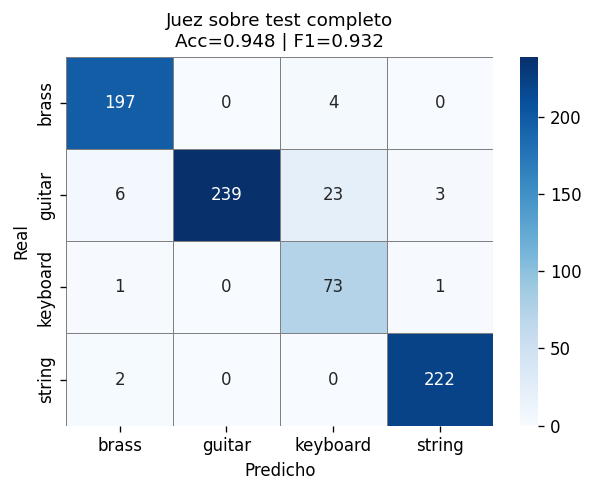

In [89]:
@torch.no_grad()
def predecir(mels, batch_size=16):
    '''Devuelve (clases predichas, confianza, logits) para mels (N, 1, 128, 128).'''
    if not torch.is_tensor(mels):
        mels = torch.as_tensor(np.asarray(mels), dtype=torch.float32)
    if mels.ndim == 3:
        mels = mels[:, None]
    mels = mels.float()

    preds, confs, logits = [], [], []
    for i in range(0, len(mels), batch_size):
        x = mels[i:i + batch_size].to(device)
        with torch.cuda.amp.autocast(enabled=use_amp):
            lg = juez(x)
        lg = lg.float()
        p = lg.softmax(1)
        preds.append(p.argmax(1).cpu())
        confs.append(p.max(1).values.cpu())
        logits.append(lg.cpu())
    return (torch.cat(preds).numpy(), torch.cat(confs).numpy(), torch.cat(logits).numpy())


def evaluar(nombre, mels, y_true):
    '''Evalúa un conjunto de mels contra sus etiquetas y devuelve un dict de métricas.'''
    y = np.asarray(y_true.detach().cpu() if torch.is_tensor(y_true) else y_true)
    pred, conf, _ = predecir(mels)
    res = {
        'conjunto': nombre,
        'n': int(len(y)),
        'accuracy': float(accuracy_score(y, pred)),
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)),
        'confianza_media': float(conf.mean()),
    }
    print(f"[INFO] {nombre:34s} n={res['n']:4d} | acc={res['accuracy']:.4f} | "
          f"F1={res['f1_macro']:.4f} | conf={res['confianza_media']:.3f}")
    return res, pred, conf


res_test, pred_test, conf_test = evaluar('Real (test completo)', X_test, y_test)
res_test20, pred_test20, conf_test20 = evaluar('Real (test, 20 condiciones)', X_test_cond, y_test_cond)

print('\n[INFO] Reporte del juez sobre el subconjunto de 20 condiciones:')
print(classification_report(y_test_cond.numpy(), pred_test20,
                            target_names=FAMILY_NAMES, zero_division=0))

fig, ax = plt.subplots(1, 1, figsize=(5.2, 4.2), dpi=120)
cm = confusion_matrix(y_test.numpy(), pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=FAMILY_NAMES, yticklabels=FAMILY_NAMES,
            linewidths=0.5, linecolor='gray')
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title(f'Juez sobre test completo\nAcc={res_test["accuracy"]:.3f} | '
             f'F1={res_test["f1_macro"]:.3f}', fontsize=11)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'juez_test_cm.png', dpi=120, bbox_inches='tight')
plt.show()

## 5. El torneo

### ¿Qué se hace a continuación?
Se evalúan los cuatro candidatos con el mismo `evaluar()`: baseline de media (20 condiciones), VAE (80 muestras), Flow Matching (80 muestras) y la referencia real del subconjunto. Se arma la tabla comparativa y las matrices de confusión de los tres generadores.

### ¿Por qué se hace?
Es el resultado central del proyecto. La tabla responde las dos preguntas del anteproyecto de una vez: si cada generador supera el 50 % de accuracy y si supera al baseline de media. La confianza media agrega un dato que la accuracy esconde: un modelo puede acertar poco pero con seguridad alta (y equivocarse siempre en lo mismo), o acertar con la misma frecuencia que el baseline pero con una distribución de probabilidad mucho más informada.

[INFO] Baseline media                     n=  80 | acc=0.5750 | F1=0.5000 | conf=0.874
[INFO] VAE (NB03)                         n=  80 | acc=0.6375 | F1=0.5848 | conf=0.893
[INFO] Flow Matching                      n=  80 | acc=1.0000 | F1=1.0000 | conf=0.921

[INFO] ===== TORNEO (juez AST-FullFT) =====
                   conjunto  n  accuracy  f1_macro  confianza_media
              Flow Matching 80    1.0000    1.0000           0.9211
Real (test, 20 condiciones) 77    0.9221    0.8950           0.8983
                 VAE (NB03) 80    0.6375    0.5848           0.8928
             Baseline media 80    0.5750    0.5000           0.8740


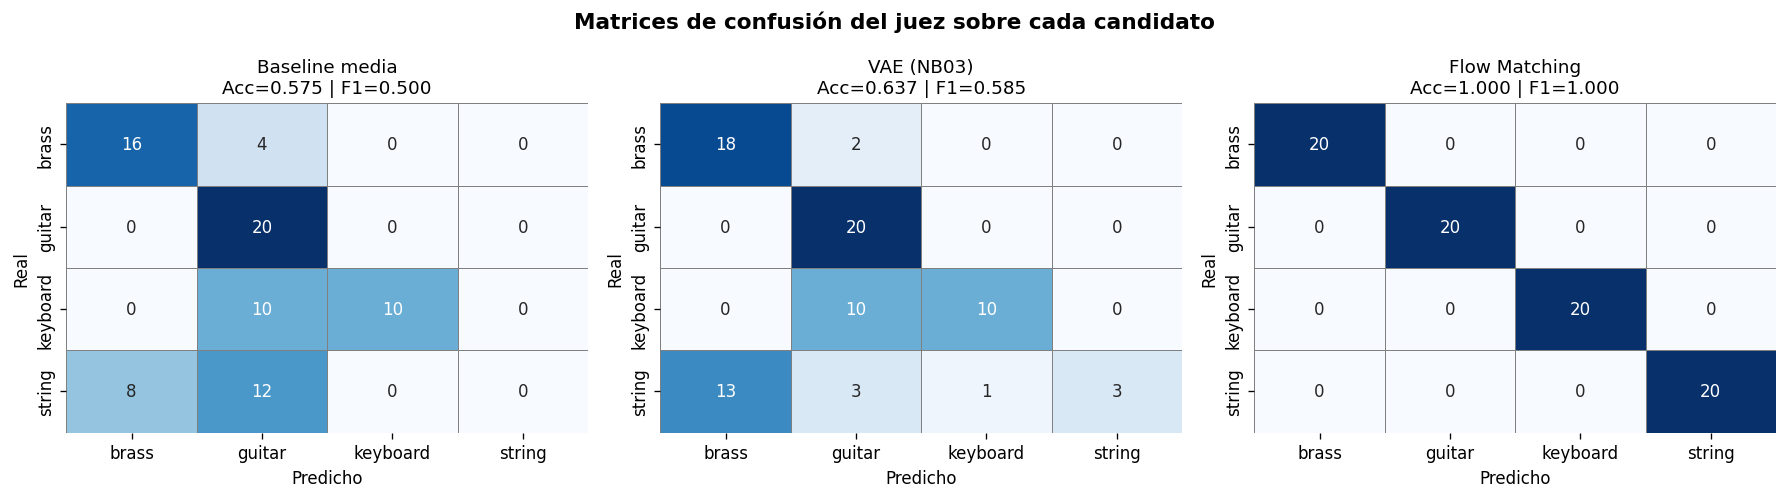

In [90]:
SETS = {
    'Baseline media': {
        'mels': baseline_mels,
        'y': y_cond,
        'p': p_cond,
        'color': '#95a5a6',
    },
}
if vae_mels is not None:
    SETS['VAE (NB03)'] = {'mels': vae_mels, 'y': vae_f.numpy(), 'p': vae_p.numpy(),
                          'color': '#8e44ad'}
SETS['Flow Matching'] = {'mels': cfm_mels, 'y': cfm_f.numpy(), 'p': cfm_p.numpy(),
                         'color': '#2980b9'}

resultados = {'Real (test, 20 condiciones)': res_test20}
predicciones = {'Real (test, 20 condiciones)': pred_test20}

for nombre, datos in SETS.items():
    res, pred, conf = evaluar(nombre, datos['mels'], datos['y'])
    resultados[nombre] = res
    predicciones[nombre] = pred
    datos['pred'] = pred

df_torneo = pd.DataFrame(list(resultados.values()))[
    ['conjunto', 'n', 'accuracy', 'f1_macro', 'confianza_media']
].sort_values('accuracy', ascending=False)

print(f'\n[INFO] ===== TORNEO (juez {JUEZ}) =====')
print(df_torneo.round(4).to_string(index=False))

# ── Matrices de confusión ───────────────────────────────────────────────────
n_paneles = len(SETS)
fig, axes = plt.subplots(1, n_paneles, figsize=(5 * n_paneles, 4.2), dpi=120)
if n_paneles == 1:
    axes = [axes]
for ax, (nombre, datos) in zip(axes, SETS.items()):
    cm = confusion_matrix(datos['y'], datos['pred'], labels=range(NUM_FAMILIES))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=FAMILY_NAMES, yticklabels=FAMILY_NAMES,
                linewidths=0.5, linecolor='gray', cbar=False)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
    ax.set_title(f"{nombre}\nAcc={resultados[nombre]['accuracy']:.3f} | "
                 f"F1={resultados[nombre]['f1_macro']:.3f}", fontsize=11)
plt.suptitle('Matrices de confusión del juez sobre cada candidato', fontsize=13,
             fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'torneo_cm.png', dpi=120, bbox_inches='tight')
plt.show()

## 6. Dónde falla cada generador

### ¿Qué se hace a continuación?
Se calcula la accuracy por `(familia, pitch)` para VAE y Flow Matching en una grilla 4×5, y el recall por familia de cada candidato contra la referencia real. Se grafican lado a lado.

### ¿Por qué se hace?
La accuracy agregada mezcla dos problemas distintos: que el modelo no genere la familia pedida, o que el juez no reconozca una familia que sí está bien generada. La grilla por condición muestra si las fallas se concentran en alturas extremas (36 y 84, donde hay menos energía armónica en la banda mel) o en una familia puntual (keyboard, la minoritaria en `train`). El recall por familia, comparado con el del test real, separa el error del generador del sesgo del juez, con la salvedad de que la referencia real tiene pocas muestras por familia (6 en keyboard) y su recall es una estimación gruesa.

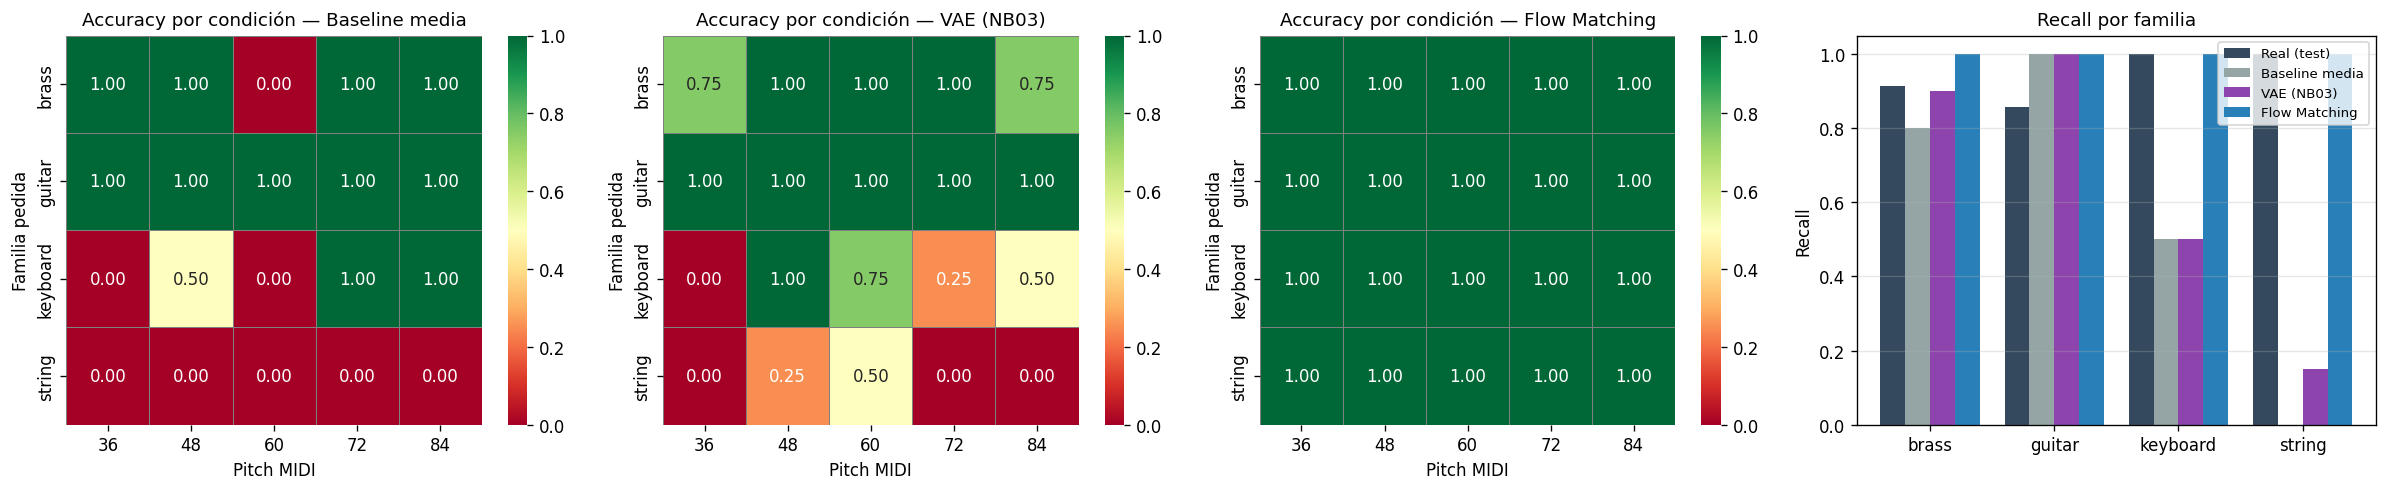

In [91]:
def accuracy_por_condicion(pred, fams, pits):
    '''Grilla 4 x 5 con la accuracy de cada (familia, pitch).'''
    fams = np.asarray(fams); pits = np.asarray(pits)
    grilla = np.full((NUM_FAMILIES, len(GEN_PITCHES)), np.nan)
    for i, f in enumerate(range(NUM_FAMILIES)):
        for j, p in enumerate(GEN_PITCHES):
            mask = (fams == f) & (pits == p)
            if mask.sum() > 0:
                grilla[i, j] = (pred[mask] == f).mean()
    return grilla


def recall_por_familia(y, pred):
    y = np.asarray(y); pred = np.asarray(pred)
    return np.array([(pred[y == f] == f).mean() if (y == f).sum() else np.nan
                     for f in range(NUM_FAMILIES)])


comparables = [n for n in SETS if len(SETS[n]['y']) > 20]
fig, axes = plt.subplots(1, len(comparables) + 1, figsize=(5 * (len(comparables) + 1), 4.2),
                         dpi=120)
if len(comparables) + 1 == 1:
    axes = [axes]

for ax, nombre in zip(axes, comparables):
    datos = SETS[nombre]
    grilla = accuracy_por_condicion(datos['pred'], datos['y'], datos['p'])
    sns.heatmap(grilla, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax, vmin=0, vmax=1,
                xticklabels=GEN_PITCHES, yticklabels=FAMILY_NAMES,
                linewidths=0.5, linecolor='gray')
    ax.set_xlabel('Pitch MIDI'); ax.set_ylabel('Familia pedida')
    ax.set_title(f'Accuracy por condición — {nombre}', fontsize=11)

ax = axes[-1]
ancho = 0.8 / (len(SETS) + 1)
for k, (nombre, datos) in enumerate([('Real (test)', {'y': y_test_cond.numpy(), 'pred': pred_test20,
                                                     'color': '#34495e'})] + list(SETS.items())):
    vals = recall_por_familia(datos['y'], datos['pred'])
    ax.bar(np.arange(NUM_FAMILIES) + (k - (len(SETS) / 2)) * ancho, vals, width=ancho,
           label=nombre, color=datos.get('color', '#34495e'))
ax.set_xticks(np.arange(NUM_FAMILIES)); ax.set_xticklabels(FAMILY_NAMES)
ax.set_ylim(0, 1.05); ax.set_ylabel('Recall')
ax.set_title('Recall por familia', fontsize=11)
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'torneo_por_condicion.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Selección por duración: la variable que no está en la condición

### ¿Qué se hace a continuación?
Para cada condición se calcula la duración mediana real de la nota en `train` (último frame a menos de 20 dB del pico). Después, de las 4 semillas que ya existen por condición, se elige la muestra cuya duración está más cerca de esa mediana, y se evalúa ese set de 20 muestras contra dos controles justos: la misma cantidad de muestras tomando la semilla 42 al azar, y el set completo de 80 ya evaluado en la sección 5.

### ¿Por qué se hace?
El diagnóstico del NB04 mostró que la duración y la envolvente son la falla principal y que **no están en la condición**: el modelo recibe familia y altura, y muestrea libremente si la nota dura 3 s o 0,4 s. Un brass de 0,4 s es un error, un string de 0,4 s puede ser legítimo. Elegir por duración no cambia el modelo ni gasta GPU, y mide cuánto del error del juez se explica por esa variable libre. Es *best-of-4* y hay que declararlo así: se reporta junto al control de 1-de-4 para que la comparación sea honesta.

In [92]:
def fin_de_nota(mel, caida_db=20.0):
    '''Último frame que está a menos de caida_db del pico de la propia nota.

    Los mels se normalizaron con power_to_db(ref=np.max): el pico de cada nota
    está en 0 dB y el piso en -80 dB, así que el umbral es relativo al pico.
    '''
    perfil = np.asarray(mel).max(axis=0) * 40.0 - 40.0
    pico = float(perfil.max())
    if not np.isfinite(pico) or pico < -60.0:
        return 0
    activo = np.where(perfil > pico - caida_db)[0]
    return int(activo[-1] + 1) if len(activo) else 0


def dur_s(frames):
    return frames * HOP / SR


fin_train = np.array([fin_de_nota(m) for m in X_train[:, 0].numpy()])
y_tr, p_tr = y_train.numpy(), p_train.numpy()

objetivo = {}
for f, p in CONDICIONES:
    mask = (y_tr == f) & (p_tr == p)
    if mask.sum() >= 5:
        objetivo[(f, p)] = float(np.median(fin_train[mask]))
    else:
        objetivo[(f, p)] = float(np.median(fin_train[y_tr == f]))

print('[INFO] Duración mediana real por condición (s):')
print(pd.DataFrame([{'familia': FAMILY_NAMES[f], 'pitch': p, 'dur_real_s': dur_s(objetivo[(f, p)])}
                    for f, p in CONDICIONES]).pivot(index='familia', columns='pitch',
                                                    values='dur_real_s').round(2).to_string())


def seleccionar_por_duracion(mels, fams, pits, objetivo):
    '''Índice de la muestra de cada condición más cercana en duración a la real.'''
    fams = np.asarray(fams); pits = np.asarray(pits)
    elegidos = []
    for f, p in CONDICIONES:
        idx = np.where((fams == f) & (pits == p))[0]
        if len(idx) == 0:
            continue
        d = np.array([fin_de_nota(m) for m in mels[idx, 0].numpy()])
        elegidos.append(int(idx[np.argmin(np.abs(d - objetivo[(f, p)]))]))
    return np.array(elegidos)


def subconjunto(mels, fams, pits, sem, semilla):
    idx = np.where(sem == semilla)[0]
    return mels[idx], np.asarray(fams)[idx], np.asarray(pits)[idx]


def error_duracion(mm, ff, pp):
    '''Error absoluto mediano de duración (s) contra la mediana real de la condición.'''
    d = np.array([fin_de_nota(x) for x in mm[:, 0].numpy()])
    obj = np.array([objetivo[(int(a), int(b))] for a, b in zip(ff, pp)])
    return float(np.median(np.abs(d - obj))) * HOP / SR


filas_sel = []
resumen_sel = {}
sets_sel = {}

for nombre, mels, fams, pits, sem in [
    ('Flow Matching', cfm_mels, cfm_f.numpy(), cfm_p.numpy(), cfm_sem),
    ('VAE (NB03)', vae_mels, vae_f.numpy() if vae_f is not None else None,
     vae_p.numpy() if vae_p is not None else None, vae_sem),
]:
    if mels is None:
        continue

    # 1 de N: una muestra por condición, sin mirar la duración
    semillas = sorted(set(sem.tolist()))
    semilla_base = int(semillas[0])
    m1, f1, p1 = subconjunto(mels, fams, pits, sem, semilla_base)
    etiqueta_1deN = f'1 de {len(semillas)} (semilla {semilla_base})'
    res1, pred1, _ = evaluar(f'{nombre} · {etiqueta_1deN}', m1, f1)

    # mejor de N por duración
    idx = seleccionar_por_duracion(mels, fams, pits, objetivo)
    m2, f2, p2 = mels[idx], fams[idx], pits[idx]
    etiqueta_sel = f'mejor de {len(semillas)} por duración'
    res2, pred2, _ = evaluar(f'{nombre} · {etiqueta_sel}', m2, f2)

    e1 = error_duracion(m1, f1, p1)
    e2 = error_duracion(m2, f2, p2)
    filas_sel.append({'modelo': nombre, 'protocolo': etiqueta_1deN,
                      'accuracy': res1['accuracy'], 'f1_macro': res1['f1_macro'],
                      'error_dur_mediana_s': e1})
    filas_sel.append({'modelo': nombre, 'protocolo': etiqueta_sel,
                      'accuracy': res2['accuracy'], 'f1_macro': res2['f1_macro'],
                      'error_dur_mediana_s': e2})
    resumen_sel[nombre] = {'1_de_N': res1, 'mejor_de_N': res2,
                           'error_dur_1': e1, 'error_dur_sel': e2}
    sets_sel[nombre] = {'mels': m2, 'f': np.asarray(f2), 'p': np.asarray(p2)}

df_sel = pd.DataFrame(filas_sel)
print('\n[INFO] ===== SELECCIÓN POR DURACIÓN (una muestra por condición) =====')
print(df_sel.round(4).to_string(index=False))

[INFO] Duración mediana real por condición (s):
pitch       36    48    60    72    84
familia                               
brass     3.12  3.09  3.09  3.09  3.06
guitar    2.11  1.97  0.91  0.83  0.53
keyboard  3.03  3.03  1.95  0.75  0.56
string    3.19  3.16  3.12  3.09  3.12
[INFO] Flow Matching · 1 de 4 (semilla 42) n=  20 | acc=1.0000 | F1=1.0000 | conf=0.925
[INFO] Flow Matching · mejor de 4 por duración n=  20 | acc=1.0000 | F1=1.0000 | conf=0.924
[INFO] VAE (NB03) · 1 de 4 (semilla 42)   n=  20 | acc=0.6000 | F1=0.5128 | conf=0.888
[INFO] VAE (NB03) · mejor de 4 por duración n=  20 | acc=0.6000 | F1=0.4959 | conf=0.900

[INFO] ===== SELECCIÓN POR DURACIÓN (una muestra por condición) =====
       modelo               protocolo  accuracy  f1_macro  error_dur_mediana_s
Flow Matching     1 de 4 (semilla 42)       1.0    1.0000               0.2031
Flow Matching mejor de 4 por duración       1.0    1.0000               0.0312
   VAE (NB03)     1 de 4 (semilla 42)       0.6    0.5

## 8. Escucha: la misma nota por los cuatro caminos

### ¿Qué se hace a continuación?
Se elige, por familia, el pitch de la grilla con más muestras reales en `test` (el más cercano a 60 si hay empate) y se sintetizan cuatro versiones de esa nota con **el mismo vocoder Griffin-Lim del NB03/NB04**: la real de `test`, el baseline de media, la del VAE y la del Flow Matching (la elegida por duración). Se guardan como WAV, se muestran los reproductores y se grafica la grilla de mels.

### ¿Por qué se hace?
Las métricas dicen si el juez reconoce la familia, pero no si el audio suena a algo. La escucha es la única forma de comprobar que un acierto del juez no es un artefacto de Griffin-Lim ni de la escala del mel, y de escuchar el defecto de envolvente que midió el NB04. Se usa el mismo vocoder en los cuatro casos —incluida la muestra real— para que la comparación sea de contenido y no de síntesis. El pitch no se fija en 60 a ciegas: en `test` hay condiciones con cero muestras reales (keyboard en 60, por ejemplo), y comparar contra una nota de otra altura sería peor que elegir la altura con más test.


--- BRASS | pitch 60 (7 reales en test) ---
  real:


  baseline:


  Flow Matching:


  VAE (NB03):



--- GUITAR | pitch 60 (7 reales en test) ---
  real:


  baseline:


... (6 outputs left out)


--- STRING | pitch 36 (7 reales en test) ---
  real:


  baseline:


  Flow Matching:


  VAE (NB03):


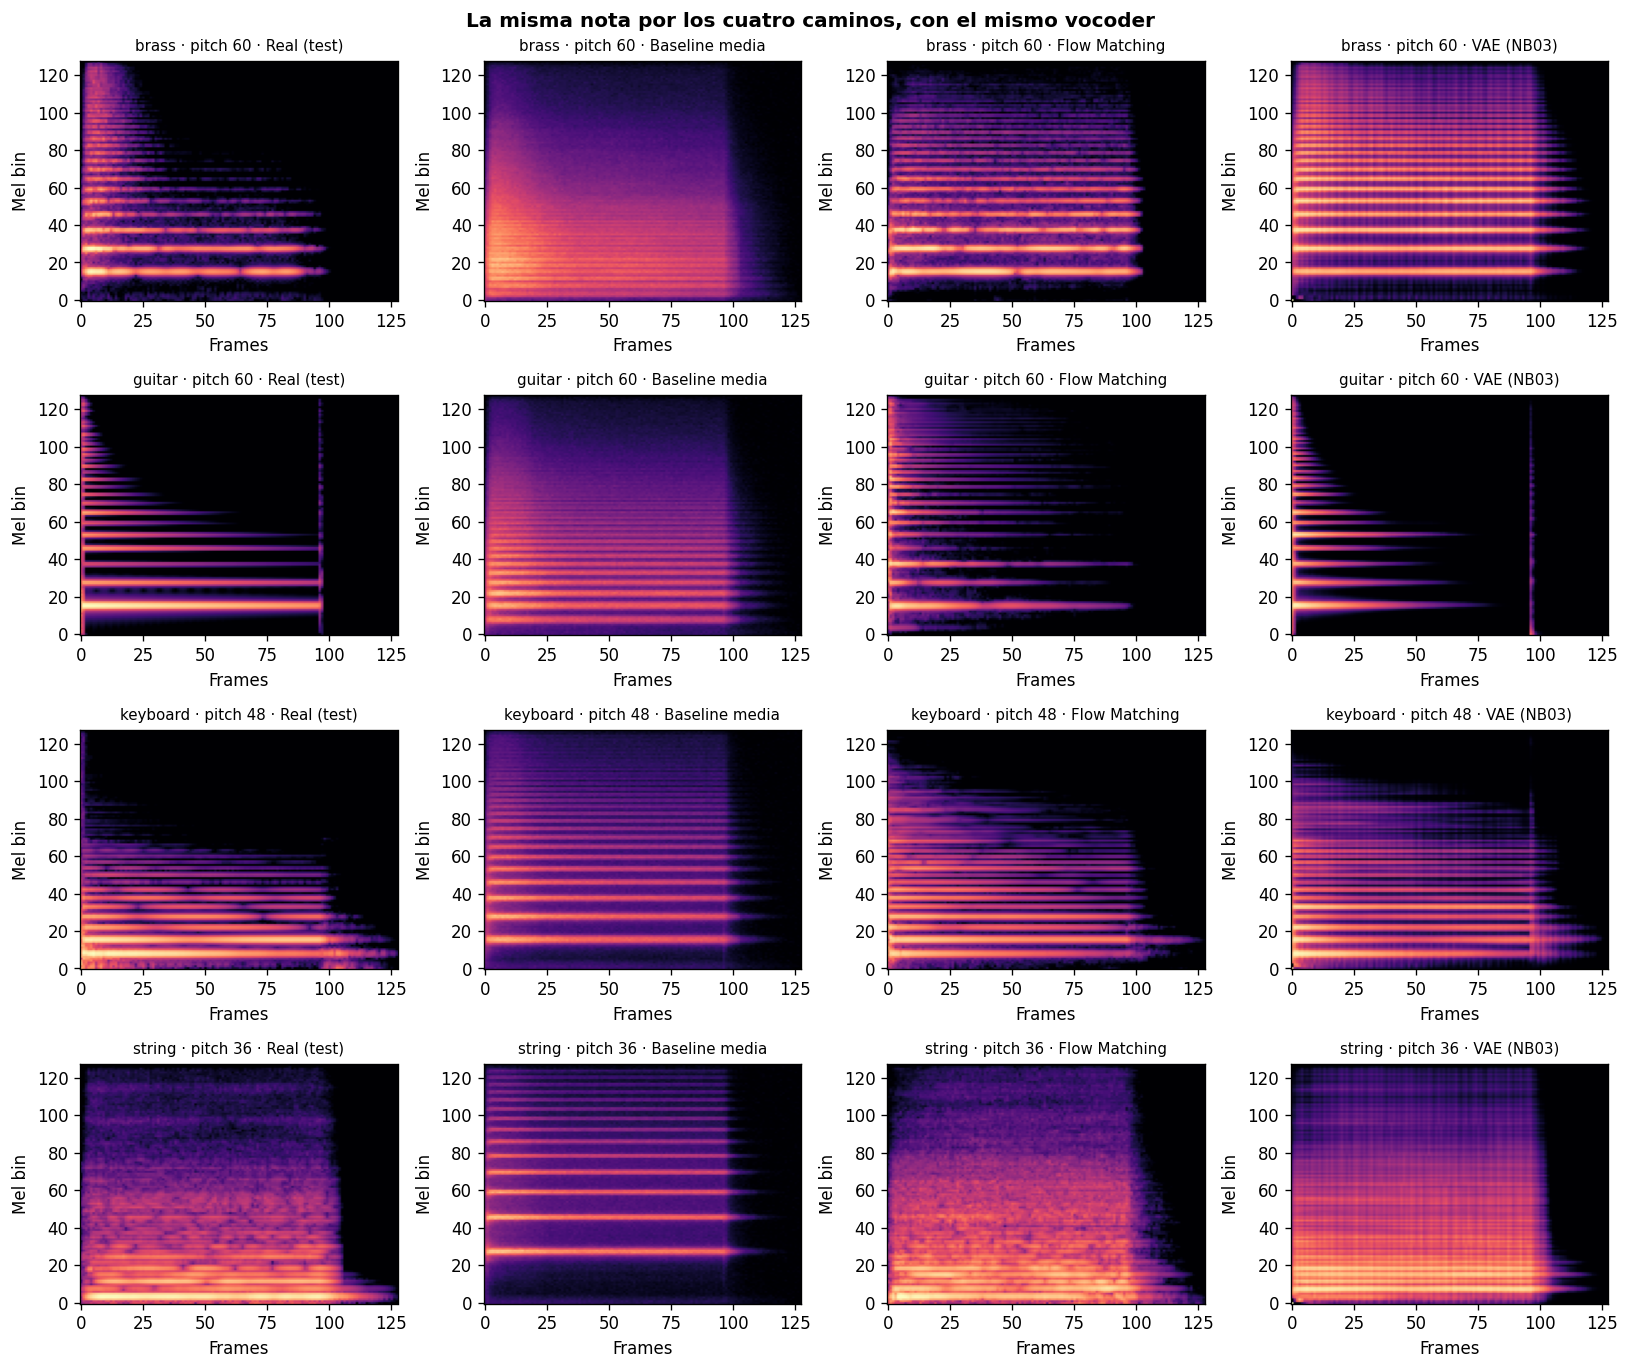

[INFO] Audios: 16 WAV en /kaggle/working/torneo_output_AST-FullFT/audio
[INFO] ZIP: /kaggle/working/torneo_output_AST-FullFT/audio_escucha.zip


In [93]:
import zipfile
import librosa
import soundfile as sf
import IPython.display as ipd

AUDIO_DIR = OUTPUT_DIR / 'audio'
AUDIO_DIR.mkdir(parents=True, exist_ok=True)
for p in AUDIO_DIR.glob('*.wav'):
    p.unlink()

# ── Vocoder idéntico al del NB03/NB04 ───────────────────────────────────────
# n_fft=2048 solo para Griffin-Lim (más solapamiento); la escala mel tiene que
# seguir siendo la del análisis: HTK, norm=None, dB = 40*v - 40.
SR_A, N_FFT_A, HOP_A = 16000, 2048, 500
GATE_DB_A, FADE_MS_A = -40.0, 15


def compuerta_suave(wav, sr, umbral_db=-40.0, rodilla_db=8.0, suav_ms=30):
    '''Atenúa el hiss de Griffin-Lim en los silencios (relativo al pico).'''
    win = max(1, int(sr * 0.02))
    if len(wav) < win:
        return wav
    env = np.sqrt(np.convolve(wav ** 2, np.ones(win) / win, mode='same'))
    ref = max(float(env.max()), 1e-12)
    db = 20.0 * np.log10(env / ref + 1e-12)
    gan = np.clip((db - (umbral_db - rodilla_db)) / rodilla_db, 0.0, 1.0)
    k = max(1, int(sr * suav_ms / 1000))
    gan = np.convolve(gan, np.ones(k) / k, mode='same')
    return (wav * gan).astype(np.float32)


def mel_a_audio(mel_norm, n_iter=250):
    '''Invierte un mel en [-1, 1] a 4 s de audio, igual que en el NB03/NB04.'''
    mel = np.asarray(mel_norm, dtype=np.float32)
    mel_power = librosa.db_to_power(mel * 40.0 - 40.0, ref=1.0)
    wav = librosa.feature.inverse.mel_to_audio(
        mel_power, sr=SR_A, n_fft=N_FFT_A, win_length=N_FFT_A, hop_length=HOP_A,
        power=2.0, n_iter=n_iter, htk=True, norm=None,
    )
    wav = np.asarray(wav, dtype=np.float32)
    if wav.size == 0:
        return wav

    objetivo = int(mel.shape[1] * HOP_A)      # 128 * 500 = 64.000 muestras
    wav = np.pad(wav, (0, objetivo - wav.size)) if wav.size < objetivo else wav[:objetivo]
    wav = wav - float(wav.mean())
    wav = compuerta_suave(wav, SR_A, umbral_db=GATE_DB_A)

    nf = int(SR_A * FADE_MS_A / 1000)
    if nf > 0 and len(wav) > 2 * nf:
        wav[:nf] *= np.linspace(0.0, 1.0, nf, dtype=np.float32)
        wav[-nf:] *= np.linspace(1.0, 0.0, nf, dtype=np.float32)

    pico = float(np.max(np.abs(wav)))
    if pico > 1e-7:
        wav = wav / pico * 0.95
    return wav.astype(np.float32)


# ── Una nota por familia, en el pitch con más test ──────────────────────────
PITCH_PREF = 60
y_tc, p_tc = y_test_cond.numpy(), p_test_cond.numpy()
filas_escucha = []

for f in range(NUM_FAMILIES):
    conteo = {p: int(((y_tc == f) & (p_tc == p)).sum()) for p in GEN_PITCHES}
    if sum(conteo.values()) == 0:
        print(f'[ADVERTENCIA] {FAMILY_NAMES[f]}: sin muestras reales en test, '
              'se omite de la escucha.')
        continue
    p_esc = sorted(conteo, key=lambda p: (-conteo[p], abs(p - PITCH_PREF)))[0]

    idx_real = np.where((y_tc == f) & (p_tc == p_esc))[0]
    mels = {'real': X_test_cond[idx_real[0], 0].numpy()}
    mels['baseline'] = baseline_mels[CONDICIONES.index((f, p_esc)), 0].numpy()
    for nombre, datos in sets_sel.items():
        idx = np.where((datos['f'] == f) & (datos['p'] == p_esc))[0]
        if len(idx):
            mels[nombre] = datos['mels'][idx[0], 0].numpy()

    wavs = {}
    for clave, mel in mels.items():
        wavs[clave] = mel_a_audio(mel, n_iter=250)
        etiqueta = clave.replace(' ', '_').replace('(', '').replace(')', '').lower()
        sf.write(AUDIO_DIR / f'{etiqueta}_{FAMILY_NAMES[f]}_p{p_esc}.wav',
                 wavs[clave], SR_A, subtype='PCM_16')

    filas_escucha.append({'familia': f, 'pitch': p_esc, 'mels': mels, 'wavs': wavs})

    print(f'\n--- {FAMILY_NAMES[f].upper()} | pitch {p_esc} '
          f'({conteo[p_esc]} reales en test) ---')
    for clave in ['real', 'baseline'] + list(sets_sel):
        if clave in wavs:
            print(f'  {clave}:')
            ipd.display(ipd.Audio(wavs[clave], rate=SR_A))

# ── Grilla de mels ──────────────────────────────────────────────────────────
columnas = ['real', 'baseline'] + list(sets_sel)
titulos = {'real': 'Real (test)', 'baseline': 'Baseline media'}
fig, axes = plt.subplots(len(filas_escucha), len(columnas),
                         figsize=(3.4 * len(columnas), 2.9 * len(filas_escucha)), dpi=120)
axes = np.atleast_2d(axes)
for fila, ej in enumerate(filas_escucha):
    for col, clave in enumerate(columnas):
        ax = axes[fila, col]
        if clave not in ej['mels']:
            ax.axis('off')
            continue
        ax.imshow(ej['mels'][clave], origin='lower', aspect='auto', cmap='magma',
                  vmin=-1, vmax=1)
        ax.set_title(f"{FAMILY_NAMES[ej['familia']]} · pitch {ej['pitch']} · "
                     f"{titulos.get(clave, clave)}", fontsize=9)
        ax.set_xlabel('Frames'); ax.set_ylabel('Mel bin')
plt.suptitle('La misma nota por los cuatro caminos, con el mismo vocoder',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'escucha_mels.png', dpi=120, bbox_inches='tight')
plt.show()

with zipfile.ZipFile(OUTPUT_DIR / 'audio_escucha.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(AUDIO_DIR.glob('*.wav')):
        z.write(p, arcname=p.name)
print(f'[INFO] Audios: {len(list(AUDIO_DIR.glob("*.wav")))} WAV en {AUDIO_DIR}')
print(f'[INFO] ZIP: {OUTPUT_DIR / "audio_escucha.zip"}')

## 9. Control de calibración

### ¿Qué se hace a continuación?
Se toma cada set generado, se lo reescala para que su media y su desvío global coincidan con los de `test`, y se vuelve a pasar por el juez. Es un diagnóstico, no el resultado oficial: las muestras que compiten son las originales.

### ¿Por qué se hace?
Un clasificador puede detectar al generador por su estadística global (un mel generado suele ser más oscuro o más brillante en promedio) en vez de por la estructura armónica. Si al alinear media y desvío la accuracy sube mucho, parte del error del torneo es de calibración del mel y no de contenido; si se mantiene igual, el juez está mirando la estructura, que es lo que queremos. Es la comprobación que separa "el generador no sabe hacer un piano" de "el generador hace un piano con otro nivel de energía".

In [94]:
def alinear_estadisticas(mels, referencia):
    '''Lleva la media y el desvío global del set a los de la referencia.'''
    m = mels.float()
    ref = referencia.float()
    return ((m - m.mean()) / (m.std() + 1e-8) * ref.std() + ref.mean()).clamp(-1, 1)


filas_cal = []
for nombre, datos in SETS.items():
    if len(datos['y']) <= 20:
        continue
    m_cal = alinear_estadisticas(datos['mels'], X_test)
    res_cal, _, _ = evaluar(f'{nombre} · alineado a test', m_cal, datos['y'])
    filas_cal.append({
        'modelo': nombre,
        'accuracy_original': resultados[nombre]['accuracy'],
        'accuracy_alineado': res_cal['accuracy'],
        'delta': res_cal['accuracy'] - resultados[nombre]['accuracy'],
    })

df_cal = pd.DataFrame(filas_cal)
print('\n[INFO] ===== CONTROL DE CALIBRACIÓN =====')
print(df_cal.round(4).to_string(index=False))

[INFO] Baseline media · alineado a test   n=  80 | acc=0.7500 | F1=0.6506 | conf=0.884
[INFO] VAE (NB03) · alineado a test       n=  80 | acc=0.6375 | F1=0.5641 | conf=0.887
[INFO] Flow Matching · alineado a test    n=  80 | acc=0.9875 | F1=0.9875 | conf=0.920

[INFO] ===== CONTROL DE CALIBRACIÓN =====
        modelo  accuracy_original  accuracy_alineado   delta
Baseline media             0.5750             0.7500  0.1750
    VAE (NB03)             0.6375             0.6375  0.0000
 Flow Matching             1.0000             0.9875 -0.0125


## 10. Veredicto y cierre

### ¿Qué se hace a continuación?
Se contrasta la tabla contra los criterios del anteproyecto (Accuracy > 50 % sobre las muestras generadas y superior al baseline de media), se guarda todo en `torneo_resultados.json` y `torneo_tabla.csv`, y se imprime el resumen.

### ¿Por qué se hace?
El cierre tiene que dejar los números en un formato que el informe pueda citar sin volver a correr nada, y el veredicto explícito: qué modelo gana, por cuánto, y con qué salvedades. Las salvedades no son un detalle: el juez tiene un techo de 0.93, el set generado es de 80 muestras y la selección por duración es *best-of-4*. Todo eso va escrito al lado del número.

In [95]:
UMBRAL_ACC = 0.50
acc_base = resultados['Baseline media']['accuracy']

filas_veredicto = []
for nombre in SETS:
    if nombre == 'Baseline media':
        continue
    acc = resultados[nombre]['accuracy']
    filas_veredicto.append({
        'modelo': nombre,
        'accuracy': acc,
        'supera_50%': bool(acc > UMBRAL_ACC),
        'supera_baseline': bool(acc > acc_base),
        'mejora_vs_baseline_pp': (acc - acc_base) * 100,
    })

df_veredicto = pd.DataFrame(filas_veredicto)
print('\n[INFO] ===== VEREDICTO vs ANTEPROYECTO =====')
print(df_veredicto.round(4).to_string(index=False))

generadores = [n for n in SETS if n != 'Baseline media']
mejor_fila = df_torneo[df_torneo['conjunto'].isin(generadores)].iloc[0]
print(f'\n[INFO] Mejor generador: {mejor_fila["conjunto"]} '
      f"(acc={mejor_fila['accuracy']:.4f}, F1={mejor_fila['f1_macro']:.4f})")
print(f'[INFO] Techo del juez (test, 20 condiciones): {res_test20["accuracy"]:.4f}')
print(f'[INFO] Baseline de media: {acc_base:.4f}')
if mejor_fila['accuracy'] <= acc_base:
    print('[ADVERTENCIA] Ningún generador supera al baseline de media: el veredicto '
          'del anteproyecto no se cumple y así hay que reportarlo.')

# ── Persistencia ────────────────────────────────────────────────────────────
resultados_json = {
    'juez': {'checkpoint': str(RUTA_JUEZ), 'modelo': JUEZ, 'config': CFG_JUEZ[JUEZ],
             'test_completo': res_test, 'test_20_condiciones': res_test20},
    'torneo': {k: v for k, v in resultados.items()},
    'seleccion_por_duracion': df_sel.round(4).to_dict(orient='records'),
    'calibracion': df_cal.round(4).to_dict(orient='records') if len(df_cal) else [],
    'veredicto': df_veredicto.round(4).to_dict(orient='records'),
    'criterio': {'umbral_accuracy': UMBRAL_ACC, 'baseline_accuracy': acc_base},
    'condiciones': [{'familia': FAMILY_NAMES[f], 'pitch': int(p)} for f, p in CONDICIONES],
    'semilla': SEED,
}
with open(OUTPUT_DIR / 'torneo_resultados.json', 'w', encoding='utf-8') as fh:
    json.dump(resultados_json, fh, indent=2, ensure_ascii=False, default=float)

df_torneo.round(4).to_csv(OUTPUT_DIR / 'torneo_tabla.csv', index=False)
df_sel.round(4).to_csv(OUTPUT_DIR / 'torneo_seleccion_duracion.csv', index=False)

print('\n[INFO] Archivos generados:')
for p in sorted(OUTPUT_DIR.glob('*')):
    if p.is_file():
        print(f'  {p.name:34s} {p.stat().st_size/1024:9.1f} KB')

with open(OUTPUT_DIR / 'resumen_torneo.txt', 'w', encoding='utf-8') as fh:
    fh.write(f'NB05 Torneo final - juez {JUEZ}\n')
    fh.write(f"techo_test_20cond={res_test20['accuracy']:.4f}\n")
    fh.write(f'baseline_media={acc_base:.4f}\n')
    for nombre in SETS:
        fh.write(f"{nombre}={resultados[nombre]['accuracy']:.4f}\n")
    fh.write(f'mejor={mejor_fila["conjunto"]}\n')
print(f"[INFO] Resumen: {OUTPUT_DIR / 'resumen_torneo.txt'}")


[INFO] ===== VEREDICTO vs ANTEPROYECTO =====
       modelo  accuracy  supera_50%  supera_baseline  mejora_vs_baseline_pp
   VAE (NB03)    0.6375        True             True                   6.25
Flow Matching    1.0000        True             True                  42.50

[INFO] Mejor generador: Flow Matching (acc=1.0000, F1=1.0000)
[INFO] Techo del juez (test, 20 condiciones): 0.9221
[INFO] Baseline de media: 0.5750

[INFO] Archivos generados:
  audio_escucha.zip                     1449.7 KB
  escucha_mels.png                      1282.8 KB
  juez_test_cm.png                        33.9 KB
  resumen_torneo.txt                       0.2 KB
  torneo_cm.png                           52.1 KB
  torneo_por_condicion.png                74.4 KB
  torneo_resultados.json                   4.1 KB
  torneo_seleccion_duracion.csv            0.3 KB
  torneo_tabla.csv                         0.2 KB
[INFO] Resumen: /kaggle/working/torneo_output_AST-FullFT/resumen_torneo.txt


## 11. Qué sigue

- **Informe**: la tabla de la sección 5 es el resultado del torneo; la de la sección 7 es el experimento que explica el error de envolvente; la sección 8 es la comprobación por escucha y la sección 9 descarta que el juez esté midiendo calibración global.
- **Si se quiere mejorar el CFM**: las dos palancas que quedan son condicionar la duración (requiere reentrenar, idealmente con la rama nueva inicializada en cero para no destruir el checkpoint) y *classifier-free guidance* (requiere dropout de condición en entrenamiento). Ninguna se puede hacer en inferencia, y por eso no están en este notebook.
- **Costo**: este notebook no entrena nada. Cargar el AST y predecir ~1.200 mels de 128×128 lleva 3-5 minutos de GPU; los 16 audios de Griffin-Lim agregan ~1 minuto de CPU. Es el notebook más barato de los cinco.
- **Limitación a declarar**: 80 muestras por generador dan un intervalo de confianza de ±11 puntos porcentuales al 95 % en el peor caso (p = 0,5), así que diferencias de 2-3 puntos no son concluyentes; la selección por duración es *best-of-4* y se reporta junto al control de 1-de-4; el juez tiene su propio techo de 0.93 y confunde las familias que confunde en real.